# 03 · Walkthrough: from one video to a fitted model, one step at a time

This notebook does the whole job the slow way, as if for the first time. Nothing is hidden behind a
command: each step is a few lines, and each is followed by a picture of what it produced.

1. **Look at a clip.** What is in the file, and why frame numbers cannot be trusted as a clock.
2. **Pixels to millimetres.** A printed checkerboard turns pixel positions into positions on the foam's face.
3. **Find the dots** in a frame where nothing is happening yet.
4. **Follow them with CoTracker3**, a pretrained point tracker, and check how good its tracks are.
5. **Turn tracks into measurements:** how far each dot moved, and how deep the bottle's cap went.
6. **Build the model** piece by piece: a block cut into small boxes, a foam that crushes, and a clock.
7. **Fit its parameters** to the tracks: the shape of the dent, the damping, the stiffness.
8. **Predict a press the model never saw**, from the cap's depth alone, and compare.

`01_reproduce.ipynb` runs the same pipeline through its command-line tool with the project's own dot
tracker, and its numbers are the ones in the README. Here the dots are followed by an off-the-shelf
tracker instead, so the last section can also say how much the purpose-built tracker matters.

**Needs:** the raw clips (link in the README) in `raw/`, and PyTorch for CoTracker3, which is downloaded
on first use (about 100 MB; CC-BY-NC licence). **Time:** about 40 minutes with a GPU the first time.
Everything is kept in `out/walkthrough/`, so a second run takes about a minute.

In [1]:
from dataclasses import replace
from pathlib import Path
import io, json, os, sys, time, warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)                                       # every path below is relative to the repo root
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)      # all-NaN frames where a dot is hidden

from press2sim import cotracker_check as CT, dots, fem, fit as F, model as M, model_report as MR
from press2sim.calib import Calibration, apply_h, board_visible, calibrate_clip, detect_corners, face_correction
from press2sim.cli import read_trials
from press2sim.config import load_config
from press2sim.pipeline import process_clip
from press2sim.tracker import find_rest
from press2sim.video import Clip, frame_times

import torch                                         # for CoTracker3
try:
    torch.from_numpy(np.zeros(1))                    # PyTorch built for NumPy 1 cannot read NumPy 2 arrays
except RuntimeError as err:
    raise RuntimeError(f"PyTorch {torch.__version__} cannot use NumPy {np.__version__}: install numpy<2 "
                       "or a newer PyTorch in this kernel's environment") from err
print(f"PyTorch {torch.__version__}, NumPy {np.__version__}, GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

RAW = Path(os.environ.get("PRESS2SIM_RAW", "raw"))   # the original .MOV clips
OUT = Path("out") / "walkthrough"                    # everything this notebook writes, and reuses on a rerun
CACHE = OUT / "model" / "cache"                      # solved blocks, so each one is solved only once
DEVICE = "cuda"                                      # "cpu" also works, far slower
EVERY = 4                                            # CoTracker sees one frame in four (more on this below)

cfg = load_config(None)                              # the block's, the dot grid's and the bottle's measured sizes
trials = {r["code"]: r for r in read_trials(Path("trials.csv"))}       # which file is which clip
for d in ("calib", "tracks", "cotracker_raw", "model"):
    (OUT / d).mkdir(parents=True, exist_ok=True)
assert (RAW / trials["H1"]["file"]).exists(), f"no clips in {RAW}: download them first (see the README)"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})


def show_photo(fig, quality=80):
    # a figure that is mostly a photograph, shown as a JPEG so the notebook stays small
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=90, bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))


def rms(a):
    return float(np.sqrt(np.nanmean(np.asarray(a) ** 2)))

PyTorch 2.3.0+cu121, NumPy 1.26.4, GPU: NVIDIA GeForce RTX 3080 Ti Laptop GPU


## 1 · Look at a clip

H1 is one press: a hand pushes a bottle into the foam block, holds it, and lifts it away. It was filmed
with an iPhone in "240 fps" slow motion. The first thing to read from the file is when each frame was
taken.

H1.MOV: 1920 x 1080, codec hevc
2719 frames in 13.60 s: 200 frames per second on average, not 240
usual gap 4.17 ms (1/240 s = 4.17 ms); 269 gaps of about 12.5 ms, each one 2 dropped frames


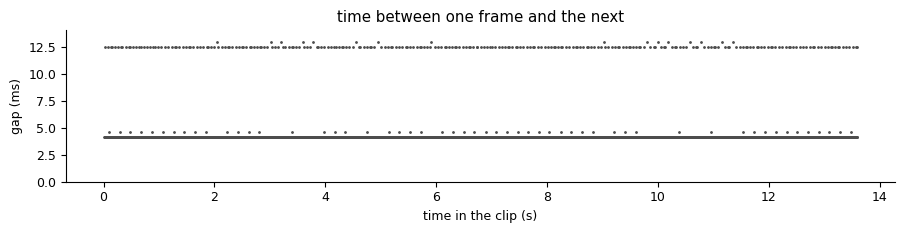

In [2]:
import av

clip_file = RAW / trials["H1"]["file"]
with av.open(str(clip_file)) as container:
    stream = container.streams.video[0]
    stamps = sorted(p.pts for p in container.demux(stream) if p.pts is not None)   # one timestamp per frame
    tick = float(stream.time_base)
    print(f"{clip_file.name}: {stream.codec_context.width} x {stream.codec_context.height}, codec {stream.codec_context.name}")
t_all = (np.array(stamps) - stamps[0]) * tick                 # seconds from the first frame
gaps = np.diff(t_all) * 1e3                                    # milliseconds between frames

print(f"{len(t_all)} frames in {t_all[-1]:.2f} s: {len(t_all) / t_all[-1]:.0f} frames per second on average, not 240")
long = gaps > 1.5 * np.median(gaps)
print(f"usual gap {np.median(gaps):.2f} ms (1/240 s = {1e3 / 240:.2f} ms); {long.sum()} gaps of about {np.median(gaps[long]):.1f} ms, "
      f"each one {round(np.median(gaps[long]) / np.median(gaps)) - 1} dropped frames")

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.plot(t_all[1:], gaps, ".", ms=2, color="0.3")
ax.set(xlabel="time in the clip (s)", ylabel="gap (ms)", ylim=(0, 14), title="time between one frame and the next")
plt.tight_layout(); plt.show()

About one frame in six is missing. Every so often the phone skips two frames at once (the gaps of
12.5 ms), all through the clip. So "frame number divided by 240" is the wrong clock. From here on every frame keeps its own
timestamp from the file.

Three frames, to see what there is to work with:

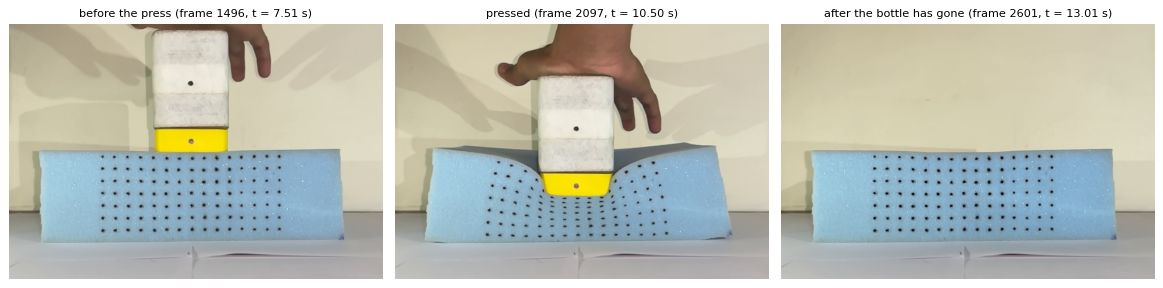

In [3]:
clip = Clip(clip_file)                                         # decodes frames upright, each with its timestamp
VIEW = (380, 130, 1480, 880)                                   # the part of the 1920 x 1080 frame with the block in it
moments = {"before the press": 7.5, "pressed": 10.5, "after the bottle has gone": 13.0}
wanted = {int(np.searchsorted(t_all, s)): name for name, s in moments.items()}
shots = {}
for i, ti, img in clip.frames(color=True, start=min(wanted), stop=max(wanted) + 1):
    if i in wanted:
        shots[i] = img

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (i, name) in zip(axs, sorted(wanted.items())):
    ax.imshow(shots[i][VIEW[1]:VIEW[3], VIEW[0]:VIEW[2], ::-1])
    ax.set_title(f"{name} (frame {i}, t = {t_all[i]:.2f} s)", fontsize=9); ax.axis("off")
plt.tight_layout(); show_photo(fig)

What can be measured from this view: the 105 black dots painted on the block's front face (15 across, 7
up, 10 mm apart), and the two dots on the bottle (one on the yellow cap, one on a strip of tape higher
up). The dots on the foam say how the foam moves. The dots on the bottle say how deep the cap is. There
is no force sensor anywhere.

## 2 · Pixels to millimetres

A dot's position in the image is in pixels. The model needs millimetres on the block's face. In clip C1 a
printed checkerboard (squares of 10 mm) stands flat against that face, so its corners are points whose
positions on the face are known.

One frame of C1 first: find the board's 250 inner corners, then find the 3 × 3 matrix (a homography)
that carries their pixel positions onto their known millimetre positions.

frame 2280 (t = 11.4 s): 250 corners, 3.74 pixels per millimetre
fit error 0.32 mm RMS; on corners left out of the fit 0.32 mm RMS, worst 0.95 mm


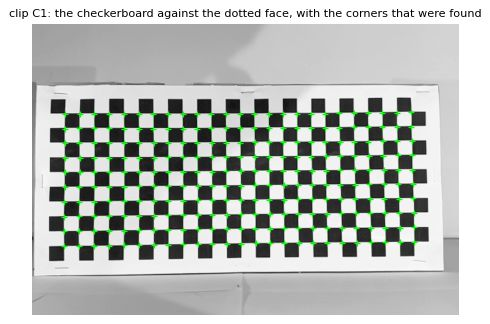

In [4]:
c1 = RAW / trials["C1"]["file"]
for i, ti, gray in Clip(c1).frames(step=120):                  # look every half second until the board is in view
    corners = detect_corners(gray, cfg) if board_visible(gray, cfg) else None      # (10, 25, 2) pixels
    if corners is not None:
        break
on_card = cfg.board.corner_xz_mm()                             # (10, 25, 2) mm: x along the face, z up from the table

H, _ = cv2.findHomography(corners.reshape(-1, 1, 2), on_card.reshape(-1, 1, 2))
fit_error = np.linalg.norm(apply_h(H, corners) - on_card, axis=-1)

# an honest check: fit on every other corner, test on the corners left out
half = np.add.outer(np.arange(10), np.arange(25)) % 2 == 0
H_half, _ = cv2.findHomography(corners[half].reshape(-1, 1, 2), on_card[half].reshape(-1, 1, 2))
left_out = np.linalg.norm(apply_h(H_half, corners[~half]) - on_card[~half], axis=-1)

scale = np.linalg.norm(np.diff(corners, axis=1), axis=-1).mean() / cfg.board.square_mm
print(f"frame {i} (t = {ti:.1f} s): {corners.shape[0] * corners.shape[1]} corners, {scale:.2f} pixels per millimetre")
print(f"fit error {rms(fit_error):.2f} mm RMS; on corners left out of the fit {rms(left_out):.2f} mm RMS, worst {left_out.max():.2f} mm")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.imshow(gray[VIEW[1]:VIEW[3], VIEW[0]:VIEW[2]], cmap="gray")
ax.plot(corners[..., 0].ravel() - VIEW[0], corners[..., 1].ravel() - VIEW[1], "+", color="lime", ms=5)
ax.set_title("clip C1: the checkerboard against the dotted face, with the corners that were found", fontsize=9); ax.axis("off")
show_photo(fig)

The left-out corners land about 0.3 mm from where they should. That is the accuracy of the map itself
(the card is not perfectly flat), and it is far coarser than how well a dot's centre can be found. It
matters less than it sounds, because the model is fitted to how far each dot *moves*, and a slowly
varying map error mostly cancels in a difference.

The project's `calibrate_clip` does the same thing with the corners averaged over every still frame.
One more correction follows. The card is only a stand-in for the face, and measured against rulers on
the foam itself (the block's height, and the distance between the top and bottom rows of dots) heights
on the face read about 5% short. `face_correction` measures that factor and where the foam's base is.

In [5]:
cal_file = OUT / "calib" / "C1.json"
if cal_file.exists():
    calib = Calibration.load(cal_file)
else:
    calib = calibrate_clip(c1, cfg)                            # corners averaged over the still frames, then the homography
    calib.report["clip"] = "C1"
    calib.report["face"] = face_correction(calib, cfg, c1, frame_times(c1).dt_median,
                                           row_span_mm=cfg.grid.measured_row_span_mm)
    calib.save(cal_file)
rep, face = calib.report, calib.report["face"]
print(f"averaged over {rep['frames_averaged']} frames: {rep['px_per_mm']:.2f} px/mm, left-out error {rep['holdout_rms_mm']:.2f} mm")
print(f"heights on the face are multiplied by {face['a_z']:.3f} (block height says {face['references']['block_height']:.3f}, "
      f"dot rows say {face['references']['dot_rows']:.3f}); the foam's base is at z = 0")
to_mm = calib.px_to_mm                                         # pixels -> (x along the face, height above the base), mm

averaged over 63 frames: 3.74 px/mm, left-out error 0.32 mm
heights on the face are multiplied by 1.049 (block height says 1.054, dot rows say 1.044); the foam's base is at z = 0


## 3 · Find the dots

A tracker needs to be told which points to follow. So the first job is to find the dots once, in a frame
where the foam is at rest.

**Which frame?** The clip starts with a sticky note held in front of the dots, then the bottle is
brought in. `find_rest` looks for the last still stretch before the press, with all 105 dots and the
bottle in view.

In [6]:
clip = Clip(clip_file, calib.report["rotation_ccw"])
rest = find_rest(clip, calib, cfg, frame_times(clip_file).dt_median, kind="press", need_bottle=True)
k0 = rest["index"]
_, gray0 = clip.frame(k0)
_, bgr0 = clip.frame(k0, color=True)
print(f"rest frame: {k0} (t = {rest['t']:.2f} s); the foam stays still until t = {rest['end_t']:.2f} s, "
      f"and the press starts at about {rest['onset_t']:.2f} s")

rest frame: 1488 (t = 7.47 s); the foam stays still until t = 7.82 s, and the press starts at about 7.93 s


**Where are the dots in it?** Each dot is a dark blob on lighter foam. Subtracting the frame from a
version of itself with the dots erased (a morphological closing, wider than a dot) leaves an image that
is bright only where something small and dark was. Each blob's centre is its brightness-weighted
centroid, and the blobs are matched to the 15 × 7 lattice.

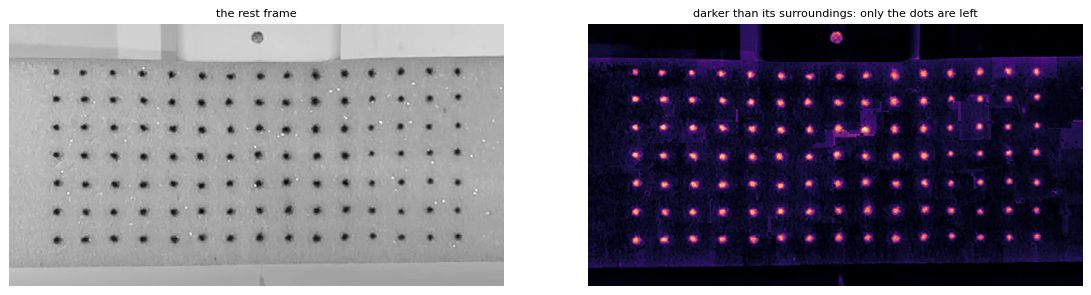

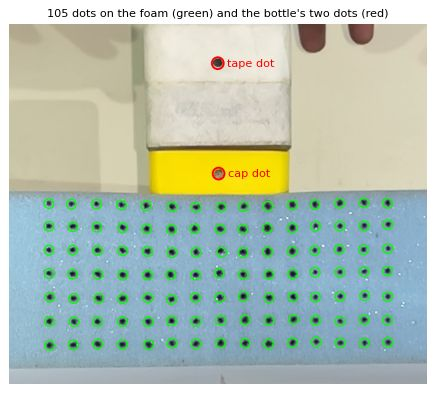

In [7]:
ppm = calib.report["px_per_mm"]
dot_px = cfg.grid.dot_diameter_mm * ppm                        # a dot is about 15 pixels across
grid_px = rest["grid_px"]                                      # (7, 15, 2): row 0 is the bottom row, column 0 the leftmost
assert np.isfinite(grid_px).all(), "a dot was not found in the rest frame"
bottle = dots.find_bottle_dots(gray0, calib, cfg, face_top_mm=cfg.block.height_mm, bgr=bgr0)

x0, y0 = (grid_px.reshape(-1, 2).min(0) - 60).astype(int)
x1, y1 = (grid_px.reshape(-1, 2).max(0) + 60).astype(int)
darkness = dots.contrast_image(gray0, (x0, y0, x1, y1), dot_px)       # how much darker than its surroundings

fig, axs = plt.subplots(1, 2, figsize=(13, 3.3))
axs[0].imshow(gray0[y0:y1, x0:x1], cmap="gray"); axs[0].set_title("the rest frame", fontsize=9)
axs[1].imshow(darkness, cmap="magma"); axs[1].set_title("darker than its surroundings: only the dots are left", fontsize=9)
for ax in axs:
    ax.axis("off")
plt.tight_layout(); show_photo(fig)

fig, ax = plt.subplots(figsize=(10, 5.2))
top = int(bottle["tape_px"][1]) - 60
ax.imshow(bgr0[top:y1, x0:x1, ::-1])
ax.scatter(grid_px[..., 0] - x0, grid_px[..., 1] - top, s=60, facecolors="none", edgecolors="lime", linewidths=1)
for name, p in (("cap dot", bottle["cap_px"]), ("tape dot", bottle["tape_px"])):
    ax.scatter(p[0] - x0, p[1] - top, s=90, facecolors="none", edgecolors="red", linewidths=1.5)
    ax.annotate(name, (p[0] - x0 + 14, p[1] - top + 4), color="red", fontsize=9)
ax.set_title(f"{np.isfinite(grid_px[..., 0]).sum()} dots on the foam (green) and the bottle's two dots (red)", fontsize=9); ax.axis("off")
show_photo(fig)

## 4 · Follow the dots with CoTracker3

[CoTracker3](https://co-tracker.github.io) is a pretrained network that follows chosen points through a
video. It is given the points in one frame (here the 105 dots and the bottle's two) and returns, for
every later frame, where each point is and whether it thinks it can still see it. It knows nothing
about foam or dots, which is the appeal: no tuning.

Two choices:

- **A crop.** Only the region around the block goes in. The network works at a fixed, low resolution
  inside, so the less background, the more pixels per dot.
- **One frame in four.** At 240 frames per second a dot moves a fraction of a pixel between frames.
  The network was trained on ordinary video, and on H1 it followed the dots better at about 50 frames
  per second than at the full rate (the error's 95th percentile while pressing fell from 3.0 to 2.6 mm),
  and two and a half times faster. The frames between are filled in by interpolating over time.

In [8]:
model = CT.load_model(DEVICE)                                  # torch.hub: facebookresearch/co-tracker, "cotracker3_online"
points0 = np.vstack([grid_px.reshape(-1, 2), bottle["cap_px"], bottle["tape_px"]])     # 105 dots, then cap dot, tape dot

raw_file = OUT / "cotracker_raw" / "H1.npz"
if raw_file.exists():
    z = np.load(raw_file); P_ct, seen = z["pts_px"].astype(float), z["visible"]
else:
    t0 = time.time()
    P_ct, seen = CT.track_points(clip, k0, points0, model, DEVICE, every=EVERY)
    print(f"tracked {P_ct.shape[1]} points through {P_ct.shape[0]} frames in {time.time() - t0:.0f} s")
    np.savez_compressed(raw_file, pts_px=P_ct.astype(np.float32), visible=seen)
t = t_all[k0:k0 + len(P_ct)]                                   # these frames' timestamps
print(f"positions {P_ct.shape} (frames, points, x and y in pixels); CoTracker says it sees {100 * seen.mean():.1f}% of them")

tracked 107 points through 1231 frames in 15 s
positions (1231, 107, 2) (frames, points, x and y in pixels); CoTracker says it sees 98.4% of them


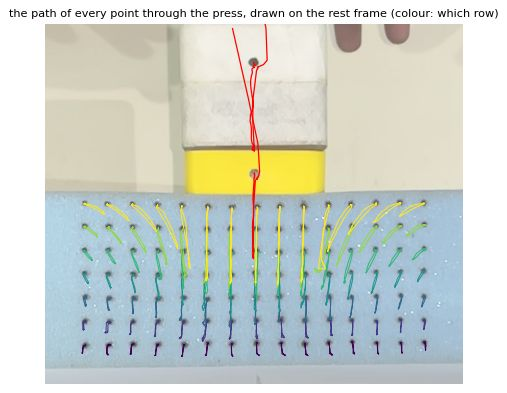

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.imshow(bgr0[top:y1, x0:x1, ::-1], alpha=0.75)
colours = plt.get_cmap("viridis")(np.repeat(np.arange(7), 15) / 6)
for j in range(105):
    ax.plot(P_ct[::8, j, 0] - x0, P_ct[::8, j, 1] - top, color=colours[j], lw=0.8)
for j in (105, 106):
    ok = seen[:, j]
    ax.plot(P_ct[ok, j, 0][::8] - x0, P_ct[ok, j, 1][::8] - top, color="red", lw=1)
ax.set_xlim(0, x1 - x0); ax.set_ylim(y1 - top, 0)
ax.set_title("the path of every point through the press, drawn on the rest frame (colour: which row)", fontsize=9); ax.axis("off")
show_photo(fig)

### How good are these tracks?

The repo carries H1's tracks from the project's own tracker (`results/tracks/H1.npz`). That tracker is
built for this scene: it finds every dark blob in every frame and takes each dot's sub-pixel centroid.
On rendered clips with known truth its dot movement is right to 0.03 mm, so here it serves as the
reference.

,frames,median distance (mm),95th percentile (mm),more than 1.5 mm off (%)
phase,,,,
"at rest, before contact",33,0.14,0.22,0.00
cap pressing,765,0.35,2.56,10.80
after the foam lets go,403,0.16,0.34,0.95


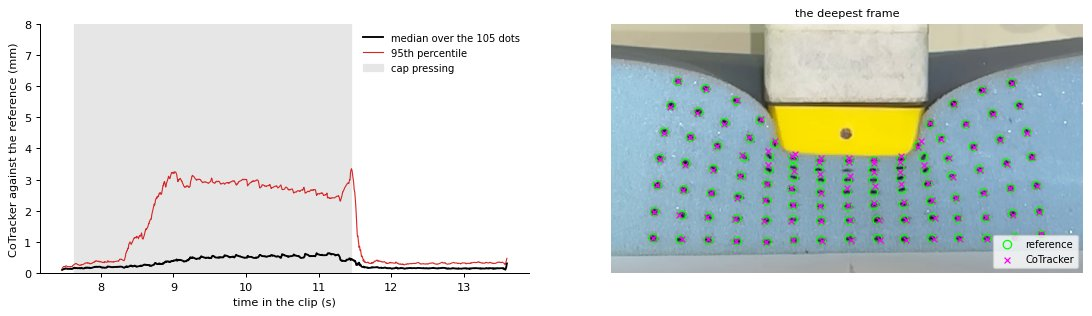

In [10]:
ref = np.load(ROOT / "results" / "tracks" / "H1.npz")
ev_ref = json.loads((ROOT / "results" / "tracks" / "H1.json").read_text())["events"]
assert int(ref["k0"]) == k0, "this notebook found a different rest frame than the reference run"
P_ref = ref["pts_px"][k0:k0 + len(P_ct)].astype(float)

apart = np.linalg.norm(to_mm(P_ct) - to_mm(P_ref), axis=-1)                # (frames, points) mm
phases = {"at rest, before contact": t < ev_ref["t_contact"],
          "cap pressing": (t >= ev_ref["t_contact"]) & (t < ev_ref["t_lift"]),
          "after the foam lets go": t >= ev_ref["t_release"]}
rows = []
for name, sel in phases.items():
    a = apart[sel][:, :105]
    rows.append([name, int(sel.sum()), np.nanmedian(a), np.nanpercentile(a, 95), 100 * np.nanmean(a > 1.5)])
display(pd.DataFrame(rows, columns=["phase", "frames", "median distance (mm)", "95th percentile (mm)", "more than 1.5 mm off (%)"])
        .set_index("phase").round(2))

k_deep = int(np.searchsorted(t, ev_ref["t_max"]))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
axs[0].plot(t, np.nanmedian(apart[:, :105], axis=1), "k", label="median over the 105 dots")
axs[0].plot(t, np.nanpercentile(apart[:, :105], 95, axis=1), color="tab:red", lw=0.9, label="95th percentile")
axs[0].axvspan(ev_ref["t_contact"], ev_ref["t_lift"], color="0.9", label="cap pressing")
axs[0].set(xlabel="time in the clip (s)", ylabel="CoTracker against the reference (mm)", ylim=(0, 8)); axs[0].legend(frameon=False, fontsize=8)
_, deep_frame = clip.frame(k0 + k_deep, color=True)
axs[1].imshow(deep_frame[y0:y1, x0:x1, ::-1])
axs[1].scatter(P_ref[k_deep, :105, 0] - x0, P_ref[k_deep, :105, 1] - y0, s=45, facecolors="none", edgecolors="lime", linewidths=1, label="reference")
axs[1].scatter(P_ct[k_deep, :105, 0] - x0, P_ct[k_deep, :105, 1] - y0, s=22, marker="x", c="magenta", linewidths=1, label="CoTracker")
axs[1].set_xlim(0, x1 - x0); axs[1].set_ylim(y1 - y0, 0)
axs[1].set_title("the deepest frame", fontsize=9); axs[1].legend(fontsize=8, loc="lower right"); axs[1].axis("off")
plt.tight_layout(); show_photo(fig, quality=85)

At rest the two trackers agree to 0.14 mm (median), and after the foam lets go to 0.16 mm. While the
cap presses they part: half the points are within 0.35 mm, but 11% are more than 1.5 mm off.

Which one is right? On rendered clips where the truth is known, the project's tracker gets each dot's
movement to 0.03 mm RMS and CoTracker to 0.24 mm (`python -m press2sim.cotracker_check --synthetic`
reruns that test), so the disagreement is mostly CoTracker's. Its worst errors here show why: about
half of the points more than 4 mm off are one dot's track sitting on another dot. Beside the cap, where
the top two rows squeeze together, one track settles on the top-row dot above it for 2.2 s. A grid of
identical dots is the hardest pattern there is for a tracker that follows appearance, because every dot
looks like its neighbours.

Then there is the bottle. Its two dots are on a rigid bottle, so their distance apart cannot change:

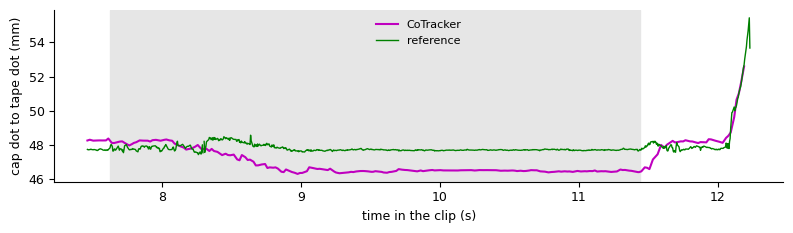

cap dot kept in 24% of the frames, tape dot in 77%


In [11]:
gap_ct = np.linalg.norm(to_mm(P_ct[:, 106]) - to_mm(P_ct[:, 105]), axis=1)
gap_ref = np.linalg.norm(to_mm(P_ref[:, 106]) - to_mm(P_ref[:, 105]), axis=1)
both = seen[:, 105] & seen[:, 106]
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot(t[both], gap_ct[both], "m", label="CoTracker")
ax.plot(t, gap_ref, "g", lw=1, label="reference")
ax.axvspan(ev_ref["t_contact"], ev_ref["t_lift"], color="0.9")
ax.set(xlabel="time in the clip (s)", ylabel="cap dot to tape dot (mm)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

keep = CT.clean(P_ct, seen, 0, 105)                           # the rule: drop the cap dot where that distance changes by more than 1.2%
print(f"cap dot kept in {100 * keep[:, 105].mean():.0f}% of the frames, tape dot in {100 * keep[:, 106].mean():.0f}%")

While the cap is in the foam, CoTracker's bottle dots come 1.8 mm closer (3.7%), while the reference
tracker's stay put: CoTracker's cap dot slides about 1.2 mm up the cap as the foam closes in around it.
A cap depth taken from that dot would read about 1.2 mm shallow all through the press.

The fix is a rule, not a better tracker. Wherever the bottle's two dots are more than 1.2% off their rest
distance, `CT.clean` drops the cap dot. The cap is then placed from the tape dot alone, with the offset
between the two dots carried over from the frames where both were trusted (`indenter.cap_path`). Here
the cap dot is dropped for most of the clip; the tape dot is lost only once the bottle leaves the
picture.

## 5 · From tracks to measurements

Positions in pixels become three things the model can use:

- **each dot's movement from rest**, in millimetres, with x measured from the block's left end and
  height from its base;
- **the cap's depth** below the foam's undisturbed top surface, from the bottle's dots (the cap's flat
  face is 8.5 mm below the cap dot and 55 mm below the tape dot, along the bottle's axis);
- **the events:** when the cap touches the foam, when it is deepest, when it starts to lift, and when the
  foam lets go of it.

`process_clip` is the project's function for exactly this. It normally calls the project's tracker;
here it is handed CoTracker instead and does everything else as usual.

In [12]:
tracker = CT.as_tracker(model, DEVICE, every=EVERY)            # CoTracker, wrapped to stand in for the project's tracker


def measure(code):
    # one clip through the pipeline with CoTracker as its tracker (skipped if already done); returns its facts
    row = trials[code]
    if not (OUT / "tracks" / f"{code}.npz").exists():
        process_clip(RAW / row["file"], code, row["kind"], calib, cfg, OUT, make_plots=False, log=lambda *a: None, tracker=tracker)
    return json.loads((OUT / "tracks" / f"{code}.json").read_text())


facts = measure("H1")
h1 = np.load(OUT / "tracks" / "H1.npz")
ev = facts["events"]
depth = float(h1["foam_top_mm"]) - h1["cap_z_mm"]             # cap depth below the undisturbed top (mm)
print({k: round(v, 2) for k, v in ev.items() if isinstance(v, float)})

{'max_depth_mm': 38.16, 't_contact': 7.6, 't_max': 11.36, 'press_speed_mm_s': 39.81, 'hold_s': 0.9, 't_lift': 11.45, 'release_speed_mm_s': 757.81, 't_release': 11.57, 'foam_top_used_mm': 72.54}


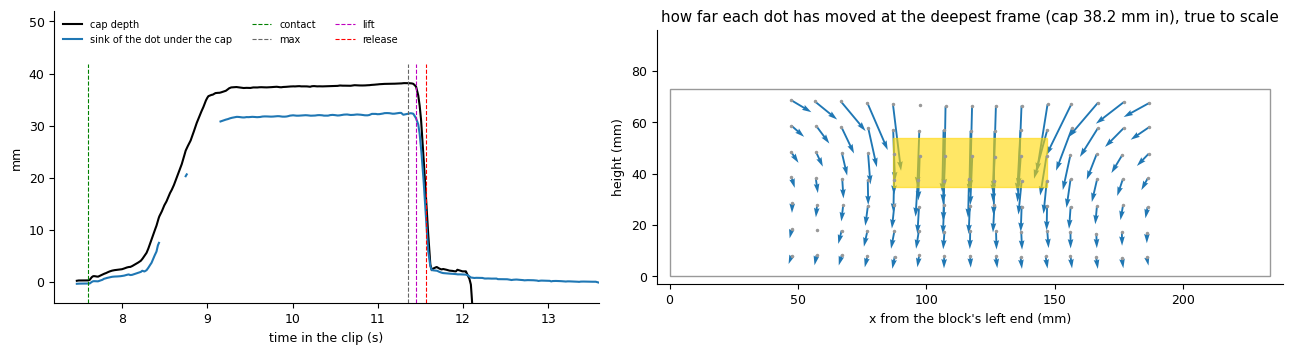

deepest: 38.2 mm here, 38.4 mm in the reference; while pressing the two depths differ by 0.29 mm RMS


In [13]:
tt, moved, at_rest = h1["t"], h1["disp_mm"], h1["rest_mm"]     # (T,), (T, 105, 2), (105, 2)
under = 90 + facts["indenter"]["column_under_cap"]             # the top-row dot under the cap
k = int(np.searchsorted(tt, ev["t_max"]))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axs[0]
ax.plot(tt, depth, "k", label="cap depth")
ax.plot(tt, -moved[:, under, 1], color="tab:blue", label="sink of the dot under the cap")
for name, col in (("t_contact", "g"), ("t_max", "0.4"), ("t_lift", "m"), ("t_release", "r")):
    ax.axvline(ev[name], ymax=0.82, color=col, ls="--", lw=0.8, label=name[2:])
ax.set(xlabel="time in the clip (s)", ylabel="mm", xlim=(ev["t_contact"] - 0.4, tt[-1]), ylim=(-4, 52)); ax.legend(frameon=False, fontsize=7, loc="upper left", ncol=3)
ax = axs[1]
ax.add_patch(plt.Rectangle((0, 0), M.BLOCK[0], M.BLOCK[2], fill=False, ec="0.6"))
ax.quiver(at_rest[:, 0], at_rest[:, 1], moved[k, :, 0], moved[k, :, 1], angles="xy", scale_units="xy", scale=1, width=0.003, color="tab:blue")
ax.plot(at_rest[:, 0], at_rest[:, 1], ".", color="0.6", ms=3)
cx = facts["indenter"]["rest_x_mm"]
ax.add_patch(plt.Rectangle((cx - 30, M.BLOCK[2] - depth[k]), 60, 19, color="gold", alpha=0.6))
ax.set(xlabel="x from the block's left end (mm)", ylabel="height (mm)", xlim=(-5, 239), ylim=(-3, 96), aspect="equal",
       title=f"how far each dot has moved at the deepest frame (cap {depth[k]:.1f} mm in), true to scale")
plt.tight_layout(); plt.show()

ref_depth = float(ref["foam_top_mm"]) - ref["cap_z_mm"]
press = (tt >= ev_ref["t_contact"]) & (tt < ev_ref["t_lift"])
print(f"deepest: {ev['max_depth_mm']:.1f} mm here, {ev_ref['max_depth_mm']:.1f} mm in the reference; "
      f"while pressing the two depths differ by {rms((depth - ref_depth)[press]):.2f} mm RMS")

The deepest point is 38.2 mm here against 38.4 mm with the reference tracker, the two depths differ by
0.29 mm RMS while the cap presses, and the events land within 0.04 s of the reference's. So with the rule
above, CoTracker's cap depth is as good as the reference's.

Two more things show in the plots. The top-row dot under the cap has a gap while the cap goes in fast
(8.4 to 9.2 s): CoTracker said it could not see it there. And that dot ends level with the cap's bottom
edge, although it started 5 mm below the surface: about 5 mm of the cap's travel never reaches the
dots. The model will have to account for that (section 6.2).

The same for every clip the fit needs: the eleven training presses, the four dead-weight clips, and the
second held-out press, O1. H1 and O1 are not used for any fitting below.

In [14]:
train_codes = [c for c, r in trials.items() if r["kind"] == "press" and r.get("held_out", "").lower() != "yes"]
weight_codes = [c for c, r in trials.items() if r["kind"] == "weight" and float(r["load_kg"] or 0) >= 0.9]
rows = []
for code in train_codes + weight_codes + ["O1"]:
    t0 = time.time()
    f = measure(code)
    e = f.get("events", {})
    rows.append([code, trials[code]["kind"], 100 * f["valid_fraction_after_rest"], e.get("max_depth_mm"), e.get("press_speed_mm_s"),
                 e.get("hold_s"), trials[code].get("load_kg") or None])
display(pd.DataFrame(rows, columns=["clip", "kind", "dots kept (%)", "deepest (mm)", "press speed (mm/s)", "hold (s)", "dead weight (kg)"])
        .set_index("clip").round(1).fillna(""))

every_clip = MR.load_set(list(trials.values()), OUT / "tracks", None)      # the measurements, in the form the model code reads
train = [every_clip[c] for c in train_codes]
weights = [every_clip[c] for c in weight_codes]

,kind,dots kept (%),deepest (mm),press speed (mm/s),hold (s),dead weight (kg)
clip,,,,,,
T01,press,99.6,23.1,25.2,0.3,
T02,press,99.3,25.0,53.3,0.8,
T03,press,98.5,19.5,17.0,0.9,
T04,press,99.2,32.8,48.0,0.4,
T05,press,99.3,31.5,23.9,0.9,
T06,press,99.1,33.8,43.3,1.8,
T07,press,99.4,45.4,41.5,0.7,
T08,press,99.2,46.0,80.3,0.3,
T09,press,98.4,47.7,53.4,1.8,


## 6 · The model, one piece at a time

The model has to answer one question: if the cap goes this deep, where does every dot go? It is built
in three layers, and each is tried before the next is added.

### 6.1 · A block cut into small boxes

The whole 234 × 139.5 × 73 mm block is cut into boxes about 7.5 mm across (finer near the dotted face,
coarser at the back). Each box resists being squashed and sheared like a small elastic cube. The base
is held by the table, the nodes under the cap are pushed down by a given depth, and solving a large
system of equations gives how far every other node moves. The dots ride on the front face: each moves
with the four nodes around it.

34 x 17 x 11 nodes, 5280 boxes, 19074 unknowns


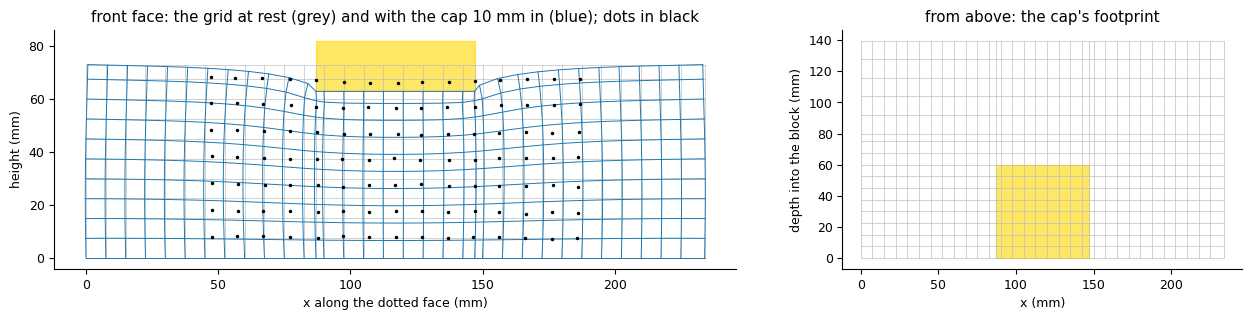

In [15]:
elastic = fem.FoamBlock(nu=0.1, eps_y=10.0, h=1.0, load=("cap", 117.0, 0.0, 60.0, 60.0), block=M.BLOCK, fine=M.FINE)
g = elastic.b                                                  # with the yield strain out of reach, this is plain linear elasticity
print(f"{g.shape[0]} x {g.shape[1]} x {g.shape[2]} nodes, {elastic.n_el} boxes, {3 * g.n_nodes} unknowns")
elastic.solve_depth(10.0)                                      # push the cap 10 mm in
face = elastic.face_nodes()                                    # (nodes along x, nodes up z, 3): the front face's movement

X, Z = np.meshgrid(g.x, g.z, indexing="ij")
fig, axs = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw={"width_ratios": [234, 139.5]})
ax = axs[0]
ax.plot(X, Z, color="0.75", lw=0.5); ax.plot(X.T, Z.T, color="0.75", lw=0.5)                       # the grid at rest
ax.plot(X + face[..., 0], Z + face[..., 2], color="tab:blue", lw=0.7); ax.plot((X + face[..., 0]).T, (Z + face[..., 2]).T, color="tab:blue", lw=0.7)
ax.add_patch(plt.Rectangle((87, 63), 60, 19, color="gold", alpha=0.6))
ax.plot(at_rest[:, 0], at_rest[:, 1], "k.", ms=3)
ax.set(aspect="equal", xlabel="x along the dotted face (mm)", ylabel="height (mm)", title="front face: the grid at rest (grey) and with the cap 10 mm in (blue); dots in black")
ax = axs[1]
Xt, Yt = np.meshgrid(g.x, g.y, indexing="ij")
ax.plot(Xt, Yt, color="0.75", lw=0.5); ax.plot(Xt.T, Yt.T, color="0.75", lw=0.5)
ax.add_patch(plt.Rectangle((87, 0), 60, 60, color="gold", alpha=0.6))
ax.set(aspect="equal", xlabel="x (mm)", ylabel="depth into the block (mm)", title="from above: the cap's footprint")
plt.tight_layout(); plt.show()

Is a plain elastic block enough? One thing makes this easy to test without knowing the stiffness. When
the cap's *depth* is given, an elastic block's shape does not depend on how stiff it is: a stiffer block
needs more force, but the dots go to the same places. So the dots can be compared straight away, with
T05, a training press about 32 mm deep.

elastic block against T05's pressing frames: 2.37 mm RMS


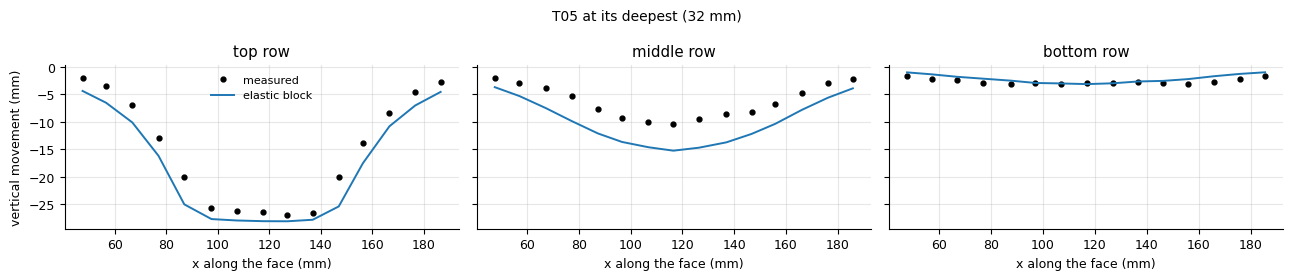

In [16]:
def moved_like(table, clip_data, p):
    # predicted movement (frames, dots, 2) of a clip's dots: the table of solved depths, driven by the clip's cap depth
    return M.predict_clip(clip_data, table, p)[0]


def rows_at_deepest(clip_data, predictions, title):
    # vertical movement along the top, middle and bottom rows of dots at the clip's deepest frame
    k = int(np.searchsorted(clip_data.t, clip_data.events["t_max"]))
    fig, axs = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
    for ax, (row, name) in zip(axs, ((6, "top row"), (3, "middle row"), (0, "bottom row"))):
        s = slice(row * 15, row * 15 + 15)
        ax.plot(clip_data.rest[s, 0], clip_data.disp[k, s, 1], "ko", ms=3.5, label="measured")
        for (label, U), style in zip(predictions.items(), ("tab:blue", "tab:orange", "tab:green")):
            ax.plot(clip_data.rest[s, 0], U[k, s, 1], color=style, lw=1.4, label=label)
        ax.set(title=name, xlabel="x along the face (mm)"); ax.grid(alpha=0.3)
    axs[0].set_ylabel("vertical movement (mm)"); axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()


no_damping = dict(g=(1e-9,), tau_v=1e-9)
p_elastic = replace(M.Params(), nu=0.1, eps_y=10.0, h=1.0, eps_d=50.0, support=1e3, **no_damping)       # elastic, on a rigid table
tab_elastic = M.build_table(p_elastic, ("cap", 117.0), cache=CACHE)       # the block solved at 10 depths up to 56 mm
t05 = every_clip["T05"]
U_elastic = moved_like(tab_elastic, t05, p_elastic)
frames_used = {c.code: M.contact_frames(c) for c in train}                # 16 frames per press, spread over its depths
print(f"elastic block against T05's pressing frames: {rms(U_elastic[frames_used['T05']] - t05.disp[frames_used['T05']]):.2f} mm RMS")
rows_at_deepest(t05, {"elastic block": U_elastic}, f"T05 at its deepest ({t05.events['max_depth_mm']:.0f} mm)")

Not good enough: 2.37 mm RMS on T05's pressing frames. The rows show what is wrong. The elastic block
spreads the cap's push too widely: in the middle row it sinks the dots under the cap 15 mm where the
real foam sank 10 mm, and the ends of the top row sink 4.4 mm instead of 2 to 3 mm. The real foam gives
way close under the cap and leaves the rest of the block more alone. Only the bottom row, which hardly
moves, comes out right.

### 6.2 · A foam that crushes

Foam is not an elastic solid. Its cells are thin struts around air. Squeezed a little, the struts bend
and the foam pushes back in proportion. Past a few percent of strain the struts buckle, and the foam
goes on shortening at almost the same stress: a plateau. Much later the collapsed cells touch each
other and the foam stiffens sharply. Three numbers describe this: the strain where buckling starts
(`eps_y`), how much the stress still rises on the plateau (`h`), and the strain where the cells start
to touch (`eps_d`).

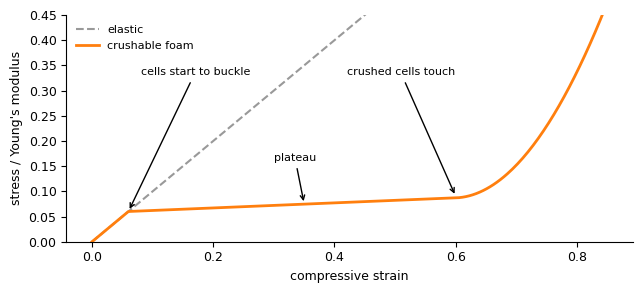

In [17]:
strain = np.linspace(0, 0.85, 300)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(strain, strain, color="0.6", ls="--", label="elastic")
ax.plot(strain, fem.foam_stress(strain, eps_y=0.06, h=0.05, eps_d=0.6), "tab:orange", lw=2, label="crushable foam")
ax.annotate("cells start to buckle", (0.06, 0.06), (0.08, 0.33), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.annotate("plateau", (0.35, 0.075), (0.3, 0.16), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.annotate("crushed cells touch", (0.6, 0.09), (0.42, 0.33), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.set(xlabel="compressive strain", ylabel="stress / Young's modulus", ylim=(0, 0.45)); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In the block, each box gets the stiffness that matches how far it is already squashed, and the solve is
repeated until the boxes' stiffnesses and strains agree. The boxes under the cap buckle first, so the
deformation concentrates there instead of spreading through the block. Solved once for a list of
depths, this gives a table: for each depth, where the face goes and how much force it takes (per unit
of Young's modulus, which is still unknown).

Two more parts were added after looking at the data, and both are simple:

- **A soft top layer.** In every press the dot 5 mm below the surface ends up almost level with the
  cap's bottom edge: about 5 mm of the cap's travel never reaches the dots. A thin, much softer layer on
  top absorbs it. The README's limitations say plainly that this layer is a stand-in.
- **A support that gives a little.** Under a dead weight the bottom row of dots sinks about half as far
  as the top row. On a rigid table it would barely move.

starting values: {'nu': 0.0, 'eps_y': 0.06, 'h': 0.01, 'eps_d': 0.64, 'y0': -3.0, 'skin_t': 3.0, 'skin_k': 0.1}


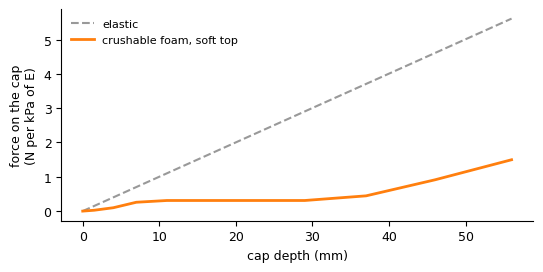

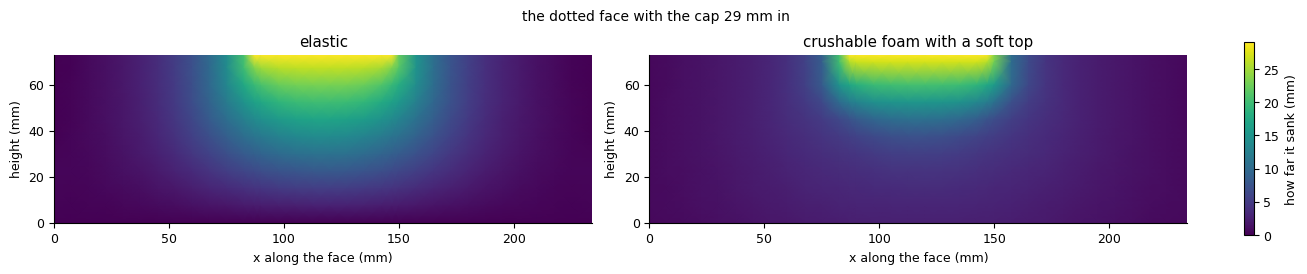

In [18]:
p_start = replace(M.Params(), **F.SHAPE_START)                 # where the fit below will start: the foam law and a soft top
tab_start = M.build_table(p_start, ("cap", 117.0), cache=CACHE)
print("starting values:", F.SHAPE_START)

fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.plot(tab_elastic.d, tab_elastic.R * 1e3, color="0.6", ls="--", label="elastic")
ax.plot(tab_start.d, tab_start.R * 1e3, "tab:orange", lw=2, label="crushable foam, soft top")
ax.set(xlabel="cap depth (mm)", ylabel="force on the cap\n(N per kPa of E)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

kd = int(np.searchsorted(tab_start.d, 29.0))
fig, axs = plt.subplots(1, 2, figsize=(13, 2.6), constrained_layout=True)
for ax, tab_, name in ((axs[0], tab_elastic, "elastic"), (axs[1], tab_start, "crushable foam with a soft top")):
    Xe, Ze = np.meshgrid(tab_.xn, tab_.zn, indexing="ij")
    im = ax.pcolormesh(Xe, Ze, -tab_.face[kd][..., 2], cmap="viridis", vmin=0, vmax=29, shading="gouraud")
    ax.set(aspect="equal", title=name, xlabel="x along the face (mm)", ylabel="height (mm)")
fig.colorbar(im, ax=axs, shrink=0.9, label="how far it sank (mm)")
fig.suptitle("the dotted face with the cap 29 mm in", fontsize=10)
plt.show()

### 6.3 · A clock

So far the foam answers instantly. Real foam does not quite: held squashed, it pushes back a little less
as time passes, and when the cap leaves, the dent it made closes over a second or so. The standard way
to describe this is to let a fraction `g` of the stiffness fade away with a time constant `tau`
(quasi-linear viscoelasticity). While the cap is in contact the foam's surface is where the cap is. If
keeping up with a rising cap would need the foam to *pull* on it, the two part and the foam comes back
on its own.

A made-up press shows what the two numbers do: 30 mm in, held for two seconds, lifted away fast. It is
run on the elastic block from 6.1, so that only the clock is at work (the crushable foam's plateau
would add wiggles of its own).

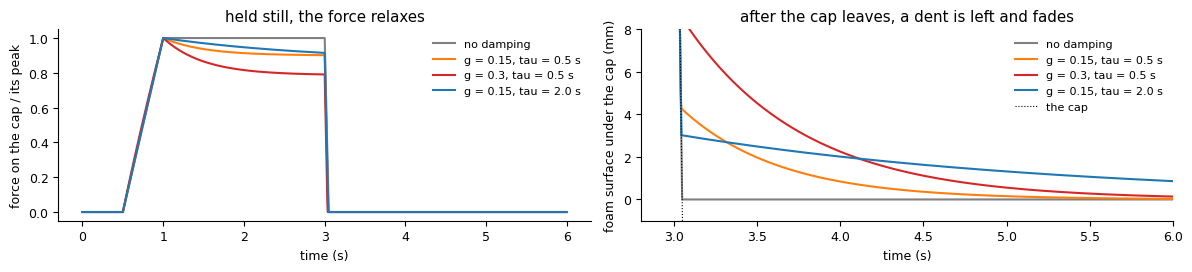

In [19]:
ts = np.arange(0, 6, 1 / 240)
cap = np.interp(ts, [0, 0.5, 1.0, 3.0, 3.1, 6.0], [-5, 0, 30, 30, -30, -30])       # depth: touch, press, hold, lift away
fig, axs = plt.subplots(1, 2, figsize=(12, 2.8))
for g_, tau_, col in ((1e-9, 0.5, "0.5"), (0.15, 0.5, "tab:orange"), (0.3, 0.5, "tab:red"), (0.15, 2.0, "tab:blue")):
    q, force, touching = M.qlv(ts, tab_elastic.d, tab_elastic.R, replace(p_elastic, g=(g_,), tau=(tau_,)), delta=cap)
    label = "no damping" if g_ < 1e-6 else f"g = {g_}, tau = {tau_} s"
    axs[0].plot(ts, force / force.max(), color=col, label=label)
    axs[1].plot(ts, q, color=col, label=label)
axs[0].set(xlabel="time (s)", ylabel="force on the cap / its peak", title="held still, the force relaxes")
axs[1].plot(ts, cap, "k:", lw=0.8, label="the cap"); axs[1].set(xlabel="time (s)", ylabel="foam surface under the cap (mm)", xlim=(2.8, 6), ylim=(-1, 8),
                                                              title="after the cap leaves, a dent is left and fades")
axs[0].legend(frameon=False, fontsize=8); axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

The force would be the obvious thing to fit `g` and `tau` to, but no force was measured. The dent is
visible, though: it is in the dots under the cap after the cap has gone.

## 7 · Fit the parameters

Three fits, one after the other, each using only the observations that can settle its parameters:

| Fit | Parameters | Fitted to | Why it can be done on its own |
|---|---|---|---|
| Shape | foam law, soft top, Poisson's ratio, cap position | the dots while the cap presses | with the depth given, damping and stiffness do not change where the dots go |
| Damping | `g`, `tau` | the dent under the cap after the foam lets go | the only place damping shows |
| Stiffness | Young's modulus `E` | how far the block sinks under known dead weights | the only clips with a known force |

### 7.1 · Shape

The score is the RMS distance between predicted and measured dots, over 16 frames from each of the
eleven training presses, chosen to spread over the depths each press went through. The search is the
simplest one there is: change one parameter a step up or down, keep the change if the score improves,
go round all the parameters twice, halving the steps the second time. Every try solves the block again
(about half a minute to a minute). The support's stiffness is fitted before and after, from the dead-weight clips.

In [20]:
t0 = time.time()
p, _, _ = F.fit_support(weights, CACHE, p_start, log=print)                 # how much the block's support gives
p, shape_rms, tried = F.fit_shape(train, CACHE, p, log=print)               # the search; every line is one solved block
p, _, _ = F.fit_support(weights, CACHE, p, log=print)
print(f"\nshape fitted in {time.time() - t0:.0f} s: {shape_rms:.2f} mm RMS on the pressing frames")

  support: 0.0600 E per mm (pattern misfit 0.113 of the sink; 0.121 if it were rigid)


  shape start: RMS 2.092 mm  (0.0, 0.06, 0.01, 0.64, -3.0, 0.06, 3.0, 0.1)


  shape skin_k=0.07: RMS 2.098 mm (51 s)


  shape skin_k=0.13: RMS 2.094 mm (49 s)


  shape skin_t=2: RMS 2.205 mm (50 s)


  shape skin_t=4: RMS 2.123 mm (48 s)


... (16 outputs left out)

  shape h=0.07: RMS 1.822 mm (31 s)


  shape eps_d=0.55: RMS 1.802 mm (28 s)


  shape nu=0.025: RMS 1.864 mm (28 s)


  support: 0.0677 E per mm (pattern misfit 0.104 of the sink; 0.110 if it were rigid)

shape fitted in 1144 s: 1.80 mm RMS on the pressing frames


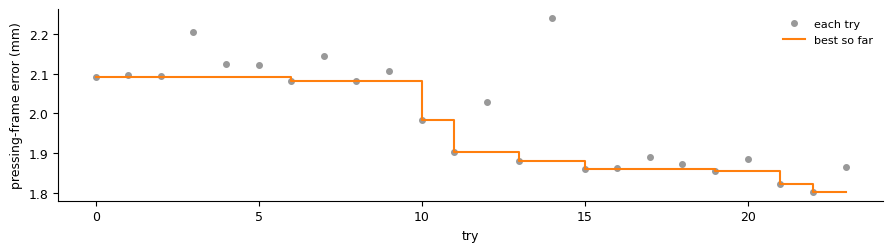

,start,fitted
Poisson's ratio,0.00,0.00000
eps_y,0.06,0.07000
h,0.01,0.07000
eps_d,0.64,0.55000
cap position (mm),-3.00,0.00000
support,0.06,0.06773
soft top (mm),3.00,3.50000
soft top stiffness,0.10,0.08500


T05's pressing frames: fitted foam 1.10 mm RMS, elastic block 2.37 mm


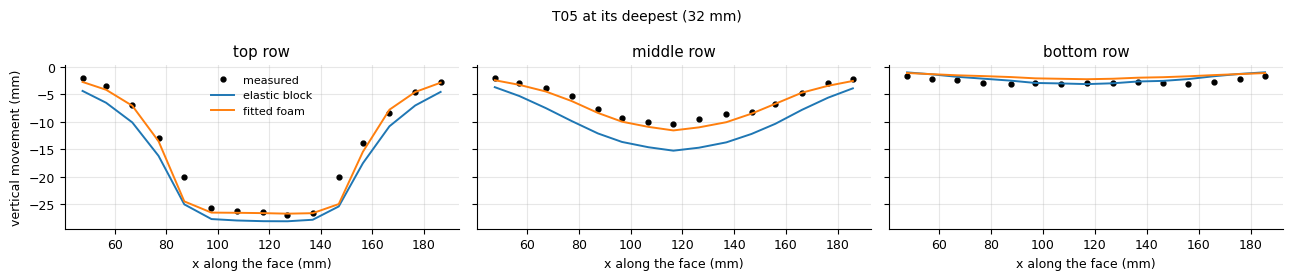

In [21]:
scores = np.array([s for _, s in tried])
names = ["Poisson's ratio", "eps_y", "h", "eps_d", "cap position (mm)", "support", "soft top (mm)", "soft top stiffness"]
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(scores, "o", color="0.6", ms=4, label="each try")
ax.step(np.arange(len(scores)), np.minimum.accumulate(scores), where="post", color="tab:orange", label="best so far")
ax.set(xlabel="try", ylabel="pressing-frame error (mm)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

fitted_shape = pd.DataFrame({"start": tried[0][0], "fitted": p.shape_key()}, index=names)
display(fitted_shape)

tab = M.build_table(p, ("cap", 117.0), cache=CACHE)
U_foam = moved_like(tab, t05, replace(p, **no_damping))
print(f"T05's pressing frames: fitted foam {rms(U_foam[frames_used['T05']] - t05.disp[frames_used['T05']]):.2f} mm RMS, "
      f"elastic block {rms(U_elastic[frames_used['T05']] - t05.disp[frames_used['T05']]):.2f} mm")
rows_at_deepest(t05, {"elastic block": U_elastic, "fitted foam": U_foam}, f"T05 at its deepest ({t05.events['max_depth_mm']:.0f} mm)")

23 tries brought the pressing-frame error from 2.09 to 1.80 mm. The foam law did most of it: the
biggest drops came from the plateau's slope (0.01 to 0.07) and from where the crushed cells start to
touch (64% to 55% strain). The soft top settled at 3.5 mm thick and 8.5% as stiff as the rest. Poisson's
ratio stayed at 0: squashed from above, this foam hardly bulges sideways. The cap's front edge came out
flush with the dotted face, which is how the presses were filmed.

On T05 the fitted foam now follows all three rows, where the elastic block missed the middle and the
top.

### 7.2 · Damping

Now the clock. For each training press, take the six top-row dots under the cap, from the moment the
foam lets go of the cap to the end of the clip, and find the `g` and `tau` that make the model's dent
close the way the measured one does.

  damping: relaxing fraction 0.192 with tau 0.497 s (dashpot held at 1.24 ms); dent under the cap after release RMS 0.311 mm (no damping 0.649 mm, 46 runs)
g = 0.192, tau = 0.50 s: the dent is predicted to 0.31 mm RMS, against 0.65 mm with no damping


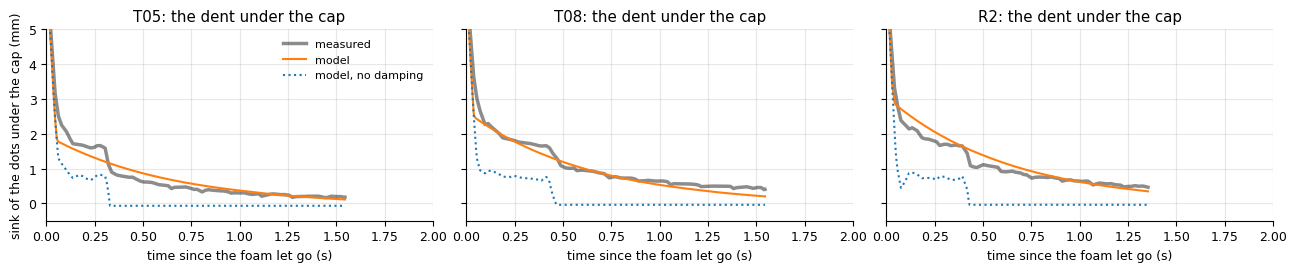

In [22]:
p, dent_rms, dent_rms_without = F.fit_time(train, tab, p, log=print)
print(f"g = {p.g[0]:.3f}, tau = {p.tau[0]:.2f} s: the dent is predicted to {dent_rms:.2f} mm RMS, against {dent_rms_without:.2f} mm with no damping")

fig, axs = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for ax, code in zip(axs, ("T05", "T08", "R2")):
    c = every_clip[code]
    w, j = F.dent_frames(c), F.dent_dots(c)
    since = c.t[w] - c.events["t_release"]
    ax.plot(since, -np.nanmean(c.disp[w][:, j, 1], axis=1), "k", lw=2.5, alpha=0.45, label="measured")
    ax.plot(since, -np.nanmean(moved_like(tab, c, p)[w][:, j, 1], axis=1), "tab:orange", label="model")
    ax.plot(since, -np.nanmean(moved_like(tab, c, replace(p, **no_damping))[w][:, j, 1], axis=1), "tab:blue", ls=":", label="model, no damping")
    ax.set(title=f"{code}: the dent under the cap", xlabel="time since the foam let go (s)", xlim=(0, 2), ylim=(-0.5, 5)); ax.grid(alpha=0.3)
axs[0].set_ylabel("sink of the dots under the cap (mm)"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

A fifth of the stiffness relaxes (g = 0.19), with a time constant of half a second. The dent under the
cap is predicted to 0.31 mm RMS, against 0.65 mm with no damping. Without damping the model's dent closes
the moment the cap has gone; the measured one fades over a second or more, and the damped model fades
with it.

### 7.3 · Stiffness

Nothing so far needed the foam's stiffness, and nothing so far could have measured it: a hand's force
leaves no trace in the video. The dead-weight clips are different. A rigid pad covers the whole top, a
known weight goes on it, and the dots sink a fraction of a millimetre. The model is solved for a plate
pressing on the whole top; how far the plate sinks is read off the dots (their movement is compared
with the pattern the model predicts for a plate). Then `E` is the stiffness that makes the model's plate
sink as far as the measured one under each weight.

  stiffness: E = 128.7 kPa (weights RMS 0.232 mm)


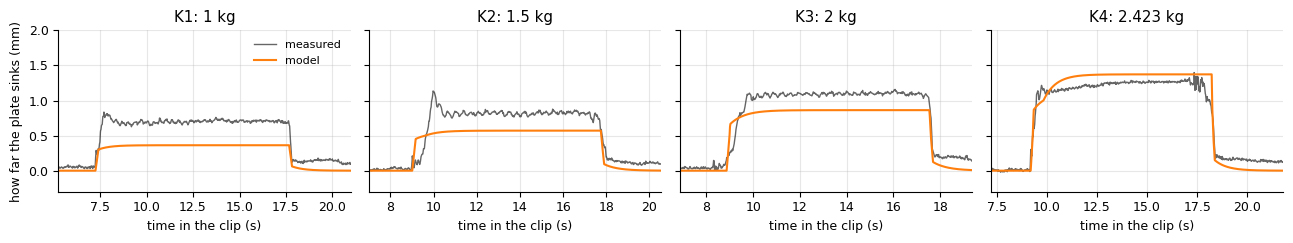

In [23]:
plate = M.build_table(p, ("plate",), cache=CACHE)              # the block under a rigid plate over its whole top
E, weight_rms, per_weight, sinks = F.fit_E(weights, plate, p, log=print)
p = replace(p, E=E)

fig, axs = plt.subplots(1, 4, figsize=(13, 2.5), sharey=True)
for ax, c in zip(axs, weights):
    sink, t_on, t_off = sinks[c.code]
    model_sink = M.predict_weight(c, plate, p, t_on, t_off)[1]
    ax.plot(c.t, sink, "k", lw=1, alpha=0.6, label="measured"); ax.plot(c.t, model_sink, "tab:orange", label="model")
    ax.set(title=f"{c.code}: {c.load_kg:g} kg", xlabel="time in the clip (s)", xlim=(t_on - 2, c.t_end), ylim=(-0.3, 2)); ax.grid(alpha=0.3)
axs[0].set_ylabel("how far the plate sinks (mm)"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

E = 129 kPa. Each weight sinks the plate by 0.7 to 1.3 mm, and one E cannot match all four: the model
gets the 2 and 2.4 kg weights roughly right and the 1 kg one at half its sink. With a millimetre of
signal, a tenth of a millimetre of tracking error is a tenth of the answer.

### 7.4 · The fitted model

Everything the three fits produced, next to the reference fit: the same code, run on the project's own
tracks (`results/model/params.json`, the numbers in the README).

In [24]:
reference = json.loads((ROOT / "results" / "model" / "params.json").read_text())["params"]
mine = {"Young's modulus E (kPa)": p.E / 1e3, "cells buckle at strain (eps_y)": p.eps_y, "plateau slope (h)": p.h,
        "crushed cells touch at strain (eps_d)": p.eps_d, "Poisson's ratio": p.nu, "soft top: thickness (mm)": p.skin_t,
        "soft top: stiffness / E": p.skin_k, "support (E per mm)": p.support, "relaxing fraction g": p.g[0], "its time constant tau (s)": p.tau[0]}
theirs = [reference["E"] / 1e3, reference["eps_y"], reference["h"], reference["eps_d"], reference["nu"], reference["skin_t"],
          reference["skin_k"], reference["support"], reference["g"][0], reference["tau"][0]]
(OUT / "model" / "params.json").write_text(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in p.__dict__.items()}, indent=1))
display(pd.DataFrame({"fitted here, on CoTracker's tracks": list(mine.values()), "reference fit": theirs}, index=list(mine)).round(3))

,"fitted here, on CoTracker's tracks",reference fit
Young's modulus E (kPa),128.693,184.784
cells buckle at strain (eps_y),0.070,0.070
plateau slope (h),0.070,0.070
crushed cells touch at strain (eps_d),0.550,0.550
Poisson's ratio,0.000,0.000
soft top: thickness (mm),3.500,3.000
soft top: stiffness / E,0.085,0.055
support (E per mm),0.068,0.030
relaxing fraction g,0.192,0.155
its time constant tau (s),0.497,0.560


The foam law came out exactly as in the reference fit: buckling at 7% strain, a plateau slope of 0.07,
densification from 55%, Poisson's ratio 0, the cap flush with the face. Those are set by the large
movements while pressing, where the two trackers agree. The damping is close: 19% relaxing at 0.50 s,
against 16% at 0.56 s.

What moved is what rests on small movements: the soft top (3.5 mm at 0.085 E, against 3.0 mm at
0.055 E), the support under the block (0.068 against 0.030 E per mm), and with them E: 129 kPa against
185 kPa, 30% lower, from the same four weights. That is the README's warning about E in practice: it
rests on sub-millimetre sinks and on two parts of the model that the dots cannot pin down.

## 8 · A press the model never saw

H1 and O1 took no part in any fit. For each, the model is given one thing: the cap's depth over time,
measured from the bottle's dots. It returns where all 105 dots should be in every frame.

The prediction is scored twice. Against CoTracker's own tracks of that press, which is all this
notebook would have without the reference. And against the project tracker's tracks of the same press,
which are the better measurement.

In [25]:
def score(code):
    c = every_clip[code]
    table = tab if abs(c.x_c - 117.0) <= 12 else M.build_table(p, ("cap", round(c.x_c, 1)), cache=CACHE)     # O1: the cap where it was
    U, surface, force, touching = M.predict_clip(c, table, p)
    careful = M.load_clip(ROOT / "results" / "tracks", code, "press")          # the same press from the project's tracker
    assert len(careful.t) == len(c.t)
    here, there = MR.metrics(c, U), MR.metrics(careful, U)
    return c, careful, U, force * p.E, [code, c.events["max_depth_mm"], here["rms_error_mm"], there["rms_error_mm"], there["rms_movement_mm"],
                                        100 * there["relative_error"], there.get("dent_error_mm")]


results = {code: score(code) for code in ("H1", "O1")}
readme = pd.read_csv(ROOT / "results" / "model" / "predictions.csv").set_index("clip")["rms_error_mm"]
table_ = pd.DataFrame([r[4] + [readme[c]] for c, r in results.items()],
                      columns=["clip", "deepest (mm)", "error against CoTracker's tracks (mm)", "error against the project tracker's tracks (mm)",
                               "RMS movement (mm)", "error / movement (%)", "dent after release (mm)", "the reference model's error (mm)"]).set_index("clip")
display(table_.round(2))

,deepest (mm),error against CoTracker's tracks (mm),error against the project tracker's tracks (mm),RMS movement (mm),error / movement (%),dent after release (mm),the reference model's error (mm)
clip,,,,,,,
H1,38.16,1.47,1.31,6.93,18.89,0.15,1.17
O1,32.63,1.18,1.13,5.21,21.70,0.21,1.01


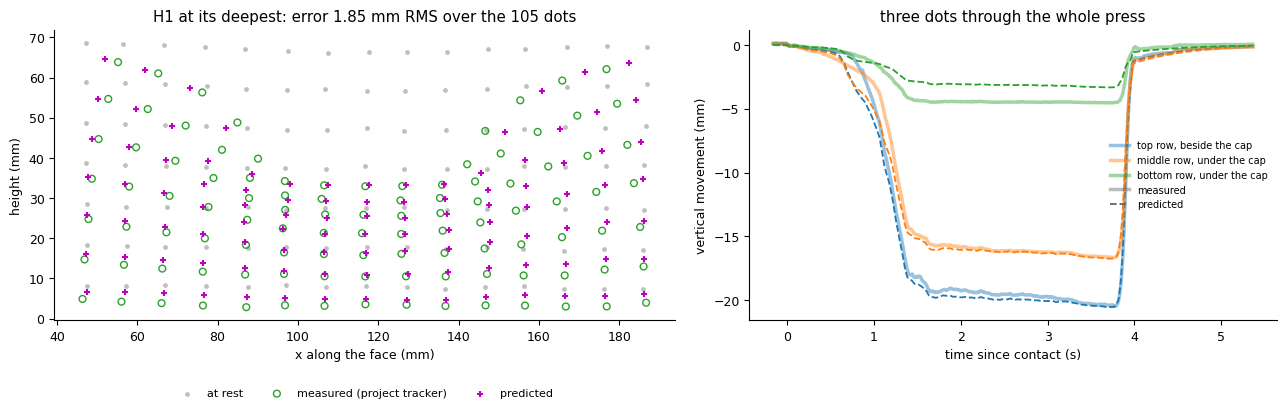

the model's estimate of the hand's force at the deepest point: 123 N (not measured; it rests on E, which is uncertain by a factor of 2 to 3)


In [26]:
c, careful, U, force, _ = results["H1"]
k = int(np.searchsorted(careful.t, careful.events["t_max"]))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axs[0]
R0 = careful.rest
ax.scatter(R0[:, 0], R0[:, 1], s=6, c="0.75", label="at rest")
ax.scatter(R0[:, 0] + careful.disp[k, :, 0], R0[:, 1] + careful.disp[k, :, 1], s=24, facecolors="none", edgecolors="tab:green", label="measured (project tracker)")
ax.scatter(R0[:, 0] + U[k, :, 0], R0[:, 1] + U[k, :, 1], s=14, marker="+", c="m", label="predicted")
ax.set(aspect="equal", xlabel="x along the face (mm)", ylabel="height (mm)", title=f"H1 at its deepest: error {rms(U[k] - careful.disp[k]):.2f} mm RMS over the 105 dots")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax = axs[1]
since = careful.t - careful.events["t_contact"]
sel = (since > -0.3) & (careful.t <= careful.t_end)
xc = c.x_c
for row, off, col, name in ((6, 36, "C0", "top row, beside the cap"), (3, 0, "C1", "middle row, under the cap"), (0, 0, "C2", "bottom row, under the cap")):
    j = row * 15 + int(np.argmin(np.abs(R0[row * 15:row * 15 + 15, 0] - (xc + off))))
    ax.plot(since[sel], careful.disp[sel, j, 1], col, lw=2.5, alpha=0.45, label=name)
    ax.plot(since[sel], U[sel, j, 1], col, ls="--", lw=1.3)
ax.plot([], [], color="0.4", lw=2.5, alpha=0.45, label="measured"); ax.plot([], [], color="0.4", ls="--", lw=1.3, label="predicted")
ax.set(xlabel="time since contact (s)", ylabel="vertical movement (mm)", title="three dots through the whole press"); ax.legend(frameon=False, fontsize=7, loc="center right")
plt.tight_layout(); plt.show()

print(f"the model's estimate of the hand's force at the deepest point: {np.nanmax(force):.0f} N "
      f"(not measured; it rests on E, which is uncertain by a factor of 2 to 3)")

Against CoTracker's own tracks of H1 the prediction is off by 1.47 mm RMS. Against the project tracker's
tracks, the better measurement, it is off by 1.31 mm, 19% of how far the dots moved; the reference fit
gets 1.17 mm. On O1 the numbers are 1.18 and 1.13 mm, against 1.01 mm. So fitting on an off-the-shelf
tracker's tracks costs about 0.13 mm on presses the model never saw. The foam law is the same, the cap
depth that drives the model is as good, and what differs is the soft top and the support. The dent
after release is predicted as well as by the reference fit (0.15 mm on H1, against 0.17 mm). The hand's
estimated force, 123 N at the deepest point, is 30% below the reference fit's 175 N, because E is.

## What came out

- **From the video:** every frame's own timestamp (the phone drops one frame in six), a map from pixels
  to millimetres good to 0.3 mm, and 105 dots plus the bottle's two followed through 17 clips.
- **The model:** a voxel block of crushable foam with a soft top layer, on a support that gives a
  little, with a clock that lets part of the stiffness relax. Ten numbers in all.
- **The fit:** the shape from the pressing frames, the damping from the dent left behind, the stiffness
  from four dead weights. On CoTracker's tracks the foam law comes out exactly as in the reference fit,
  the damping close to it, and E 30% lower.
- **The prediction:** a press the model never saw, from the cap's depth alone, to 1.31 mm RMS against
  the careful tracks (19% of how far the dots moved), where the reference fit gets 1.17 mm.

CoTracker3 is good enough to drive the model and even to fit it, but here it is not the better
measurement: on rendered clips with known truth it gets each dot's movement to 0.24 mm where the
project's tracker gets 0.03 mm, and its bottle needs a rule to stay rigid. For a soft object without
painted dots, it would be the place to start.

**Where to go from here:** `01_reproduce.ipynb` runs the pipeline with the project's own tracker and
reproduces the README's numbers; `02_check_results.ipynb` checks those numbers from the saved arrays in
a minute; `docs/model.md` has the model's limits in full.